# Composite Data

In the course so far, you might have been frustrated by working with individual images. Perhaps the image on the date you want is covered by clouds; or maybe the perfect image only covers one half of your desired area of interest. 

[Last week, we introduced the idea of compositing images through time](../07/03-temporal-change.ipynb#calculating-composite-images-through-time) to try and calculate time-averaged statistics. When you are interested in long-term change beyond the scale of individual images (e.g. comparing monthly or seasonal averages between years), it is probably a good approach to produce a 'synthetic' seasonal average, rather than trying to find a single perfect satellite image (that probably does not exist).

However, when calculating a seasonal or annual average over a wide region, downloading a sufficient number of images can become a pain! This is the advantage of computing on the cloud: rather than downloading hundreds of megabytes (or gigabytes) of data, we do our computation where the data exists, and only download the final product.

:::{warning}
Google Earth Engine non-commercial access has a variety of access tiers which define how much free EarthEngine compute you get. [These are described here](https://developers.google.com/earth-engine/guides/noncommercial_tiers) - if you followed the default instructions, you will be on the "community tier", receiving 150 hours of compute per month. This will likely be more than sufficient for most uses, but it is worth [monitoring your usage](https://developers.google.com/earth-engine/guides/monitoring_usage) if you are doing anything significant or challenging to a monthly deadline (e.g. producing data for a graded assessment!). 

**The easiest way to do check your monthly usage is to go to the [Quotas and System Limits Google Cloud page](https://console.cloud.google.com/apis/api/earthengine.googleapis.com/quotas), and examine your 'Noncommercial EECU-seconds per month' current usage percentage.** It might be worth favouriting this page.

If you're worried about blowing through all your compute on a rogue request, there are [options available to set a max compute per day](https://developers.google.com/earth-engine/guides/usage#eecu-time_per_day).
:::

In [1]:
import ee      # The main Earth Engine library
import geemap  # A Python package for interactive mapping with Google Earth Engine
import xee     # Transfer data between Earth Engine and xarray

import geopandas as gpd
import pandas as pd
import rioxarray as rxr
import xarray as xr

import matplotlib.pyplot as plt

from shapely.geometry import shape

In [2]:
# =====================================
# Replace this with your own project id
my_project_name = "ee-trchudley"
# =====================================

ee.Authenticate()
ee.Initialize(project=my_project_name) 

## A composite median image

A classic issue that requires a median image composite is heavy cloud cover. Certain regions of the globe are more susceptible to issues with cloud than others - classic examples are small islands. Here, we will take a look at the case of [Elephant Island](https://en.wikipedia.org/wiki/Elephant_Island), an Antarctic island that is most well-known for hosting the Ernest Shackleton and the rest of the Imperial Trans-Antarctic Expedition following the loss of the _Endurance_ in 1916. The crew stayed on this island for four and a half months whilst Shackleton and five others sailed all the way to South Georgia in the lifeboat _James Caird_. 

The island is very cloudy - there aren't even any good composite images [visible in Google Earth](https://www.google.com/maps/@-61.1328439,-55.0512893,41384m/data=!3m1!1e3!5m1!1e2?entry=ttu&g_ep=EgoyMDI2MTAyOC4wIKXMDSoASAFQAw%3D%3D)!

We will get a pre-existing vector outline of the island to help us define an area of interest. The British Antarctic Survey host [high-resolution vector polygons of the Antarctic coastline](https://data.bas.ac.uk/full-record.php?id=GB/NERC/BAS/PDC/01391) - I have filtered this to just Elephant Island, and you can download the geopackage below:

 - [Geopackage containing vector outline of Elephant Island, in EPSG:4326.](https://raw.githubusercontent.com/trchudley/geospatial-scientific-computing/main/week/08/elephant_island.gpkg)

Let's load and plot this:


In [3]:
island_gdf = gpd.read_file("elephant_island.gpkg")

island_gdf.explore()

We can convert a `GeoPandas` outline to a Google Earth Engine geometry using `geemap`. This allows us to use it for filtering/clipping within GEE.

In [4]:
# Convert GeoDataFrame to an Earth Engine FeatureCollection
aoi = geemap.geopandas_to_ee(island_gdf).geometry()

Let's run the same search parameters we did in the previous exercise, for summer 2023 and less than 30% cloud cover. 

In [5]:
date_min, date_max = '2023-05-01', '2023-09-30'

# Get Landsat 8 and 9 image collections, merged together
image_collection = ee.ImageCollection("LANDSAT/LC09/C02/T2_L2").merge(ee.ImageCollection("LANDSAT/LC08/C02/T2_L2"))

# Begin filtering the image collection
image_collection = (
    image_collection
    .filterBounds(aoi)                         # Filter the collection to only include images that intersect with the area of interest
    .filterDate(date_min, date_max)            # Filter the collection to only include images within the specified date range
    .filter(ee.Filter.lt("CLOUD_COVER", 30))   # Filter the collection to only include images with less than 30% cloud cover
    .sort("CLOUD_COVER")                       # Sort the collection by cloud cover in ascending order
)

image_collection

Oh dear - only two images fit our criteria over the whole summer! 

(and in fact, I've cheated here - there are no Tier 1 images at all, as these small islands frequently don't have the geolocation to support T1-standard geolocation. Note that I've changed the collections we're searching to Tier 2 imagery).

We can visualise the first image:

In [ ]:
image = image_collection.first()

image = (
    image_collection
    .first()
    .select(["SR_B2", "SR_B3", "SR_B4"])  # Select the surface reflectance bands (B2-B7)])
    .multiply(0.0000275).add(-0.2)
    .rename(["blue", "green", "red"])
    .clip(aoi)
)

map = geemap.Map()

map.centerObject(aoi, zoom=11)

# Add the raw Landsat true-colour composite
# vis_params mirrors the GEE JavaScript Code Editor convention
vis_params = {
    "bands": ["red", "green", "blue"],   # our renamed bands
    "min": 0.0,                          # surface reflectance value which corresponds to black
    "max": 1.4,                          # surface reflectance value which corresponds to white
}

# Add the image to the map with the specified visualization parameters
map.addLayer(image, vis_params, name="Landsat RGB")

# Visualise the map by calling the map object
map

...and see that it's pretty much useless, as it only covers the Eastern sliver of the island. 

Our solution here is to try and construct a median composite image of a large number of images. Given the very low amount of good-quality images, I am going to drasitically loosen our search requirements: search over five years (2020 to 2025), and raise the cloud threshold to 50%.

In [7]:
date_min, date_max = '2020-01-01', '2025-12-31'

# Get Landsat 8 and 9 image collections, merged together
image_collection = ee.ImageCollection("LANDSAT/LC09/C02/T2_L2").merge(ee.ImageCollection("LANDSAT/LC08/C02/T2_L2"))

# Begin filtering the image collection
image_collection = (
    image_collection
    .filterBounds(aoi)                         # Filter the collection to only include images that intersect with the area of interest
    .filterDate(date_min, date_max)            # Filter the collection to only include images within the specified date range
    .filter(ee.Filter.lt("CLOUD_COVER", 50))   # Filter the collection to only include images with less than 50% cloud cover
    .sort("CLOUD_COVER")                       # Sort the collection by cloud cover in ascending order
)

image_collection

We now return 59 images, which is much better.

We can calculate the median values within the image collection very simply, by using the `median()` function. In this cell, I also perform the DN conversion, rename the bands, and clip the image to our island.

In [8]:
median_image = image_collection.median()

median_image = (
    median_image
    .select(["SR_B2", "SR_B3", "SR_B4"])  # Select the surface reflectance bands (B2-B7)])
    .multiply(0.0000275).add(-0.2)
    .rename(["blue", "green", "red"])
    .clip(aoi).clip(aoi)
)

When you run this cell, you might notice it runs 'instantly', taking no time at all. This is because GEE runs 'lazily': it doesn't actually perform any computation until you ask it for an output that will require a computation to be performed - for example, by trying to plot it.

In [ ]:
map = geemap.Map()

map.centerObject(aoi, zoom=11)

# Add the raw Landsat true-colour composite
# vis_params mirrors the GEE JavaScript Code Editor convention
vis_params = {
    "bands": ["red", "green", "blue"],   # our renamed bands
    "min": 0.0,                          # surface reflectance value which corresponds to black
    "max": 1.4,                          # surface reflectance value which corresponds to white
}

# Add the image to the map with the specified visualization parameters
map.addLayer(median_image, vis_params, name="Landsat RGB")

# Visualise the map by calling the map object
map

I have chosen a very challenging example here, but we can se that it has returned a relatively good map, all things considered. We can see the texture of the ice fields as well as the peaks of the mountains. It's not perfect, but it gives us a workable start. 

## Advanced looping to retreieve annual/seasonal composites

Elephant Island is perhaps one of the most challenging possible places I could pick: most other regions will be much less harsh, and good data can be constructed even from seasonal averages.

You are welcome to use the method above to produces composites for individual seasons/years one-by-one. However, this next section shows how we can chain together slightly more complex code to automate the production of seasonal averages.

Let's return to the example of Bristol:

In [10]:
bbox = [-2.76, 51.38, -2.43, 51.53]
aoi  = ee.Geometry.BBox(*bbox)

We want to produce a median NDVI composite for each summer (June, July and August: 'JJA') between 2021 and 2026, using only scenes with less than 60% cloud cover (we can be liberal here as our median filtering will try and manage cloudier imager).

Rather than writing the same search out six times, we can wrap it into functions. The first, `calc_ndvi()`, converts a single Landsat scene to surface reflectance and calculates NDVI. The second, `summer_ndvi_composite()`, searches for all of the scenes in a given summer, calculates NDVI for each of them using the `map()` function (which applies a function to every image within an ImageCollection), and then takes the median.

We also attach two pieces of metadata to each composite using `set()`: a `system:time_start` property (GEE's standard way of recording the date of an image, which I have set to the middle of the summer), and an `n_scenes` property recording how many scenes went into the composite.

In [18]:
def calc_ndvi(image):
    """Calculate NDVI from a single Landsat 8/9 Collection 2 Level 2 scene"""
    surface_reflectance = (
        image
        .select(["SR_B4", "SR_B5"])       # Select the red and NIR bands
        .multiply(0.0000275).add(-0.2)    # Convert DN to surface reflectance
        .rename(["red", "nir"])
    )
    return surface_reflectance.normalizedDifference(["nir", "red"]).rename("ndvi")


def summer_ndvi_composite(year):
    """Produce a median summer (JJA) NDVI composite for a given year"""
    summer_collection = (
        ee.ImageCollection("LANDSAT/LC09/C02/T1_L2")          # Search for Landsat 9 Collection 2, Tier 1, Level 2 data
        .merge(ee.ImageCollection("LANDSAT/LC08/C02/T1_L2"))  # Merge with Landsat 8 Collection 2, Tier 1, Level 2 data
        .filterBounds(aoi)                                    # Filter to images that intersect with the area of interest
        .filterDate(f"{year}-06-01", f"{year}-09-01")         # Filter to June, July and August (the end date is exclusive)
        .filter(ee.Filter.lt("CLOUD_COVER", 60))              # Filter to images with less than 60% cloud cover
    )

    composite = (
        summer_collection
        .map(calc_ndvi)   # Calculate NDVI for every scene in the collection
        .median()         # Take the per-pixel median through time
        .clip(aoi)
        .set("system:time_start", ee.Date.fromYMD(year, 7, 15).millis())  # Record the date as mid-summer
        .set("n_scenes", summer_collection.size())                        # Record the number of scenes used
    )

    return composite

We can then call this function for each year, and combine the resulting composites into a single ImageCollection:

In [19]:
years = range(2021, 2027)

summer_composites = [summer_ndvi_composite(year) for year in years]

summer_composites = ee.ImageCollection(summer_composites)

summer_composites

Remember that nothing has actually been computed yet! However, we can ask GEE to compute (and send back to us) only the `n_scenes` property of each composite using `aggregate_array()`, and present it as a `pandas` table:

In [20]:
n_scenes = summer_composites.aggregate_array("n_scenes").getInfo()

pd.DataFrame({"year": years, "n_scenes": n_scenes})

,year,n_scenes
0,2021,3
1,2022,11
2,2023,9
3,2024,7
4,2025,12
5,2026,14


We can see that the number of scenes varies a lot from year to year - despite being summer, it is still Britain! In 2021, only three scenes passed our cloud filter, so the median and may appear of poorer quality.

Note also that `filterBounds()` returns any scene that *intersects* our AOI, not one that fully *covers* it. Bristol sits near the edge of two Landsat paths, so some years may only have partial coverage of our area.

### Download to an `xarray` object

As in the previous notebook, we need to define the pixel grid to download. However, there is a catch: GEE composites (such as the output of `median()`) no longer have a native projection, as they could be built from images in many different projections. If you check `summer_composites.first().projection()`, you will see it has defaulted to `EPSG:4326` at a pixel size of 1 degree!

Instead, we take the CRS and pixel size from an original Landsat scene, and the footprint from our AOI:

In [21]:
# Extract the CRS and pixel size from an original Landsat scene
landsat_scene = ee.ImageCollection("LANDSAT/LC08/C02/T1_L2").filterBounds(aoi).first()
projection = landsat_scene.select("SR_B4").projection().getInfo()
crs = projection["crs"]
grid_scale = (projection["transform"][0], projection["transform"][4])  # (x, y) pixel size: y is negative as rows run north to south

# Extract the AOI footprint as a shapely geometry
footprint = shape(aoi.getInfo())

grid = xee.helpers.fit_geometry(footprint, grid_crs=crs, grid_scale=grid_scale)

print("grid parameters:", grid)

grid parameters: {'crs': 'EPSG:32630', 'crs_transform': (30.0, 0.0, 516630.0, 0.0, -30.0, 5708940.0), 'shape_2d': (768, 561)}


We can now download the whole ImageCollection. This is the point at which GEE actually performs the computation - searching, calculating NDVI for every scene, and taking the median - before sending us only the six final composites:

In [22]:
ds = xr.open_dataset(
    summer_composites,
    engine='ee',
    **grid
)

ds = ds.rio.write_crs(crs, inplace=True)

ds = ds.compute()

ds

<xarray.Dataset> Size: 10MB
Dimensions:      (time: 6, y: 561, x: 768)
Coordinates:
  * time         (time) datetime64[ns] 48B 2021-07-15 2022-07-15 ... 2026-07-15
  * y            (y) float64 4kB 5.709e+06 5.709e+06 ... 5.692e+06 5.692e+06
  * x            (x) float64 6kB 5.166e+05 5.167e+05 ... 5.396e+05 5.397e+05
    spatial_ref  int64 8B 0
Data variables:
    ndvi         (time, y, x) float32 10MB nan nan nan nan ... nan nan nan nan

Because we set the `system:time_start` property, our `time` dimension now contains real dates. We can also add the number of scenes as an extra coordinate, so that this information travels with our dataset:

In [23]:
ds = ds.assign_coords(n_scenes=("time", n_scenes))

ds

<xarray.Dataset> Size: 10MB
Dimensions:      (time: 6, y: 561, x: 768)
Coordinates:
  * time         (time) datetime64[ns] 48B 2021-07-15 2022-07-15 ... 2026-07-15
    n_scenes     (time) int64 48B 3 11 9 7 12 14
  * y            (y) float64 4kB 5.709e+06 5.709e+06 ... 5.692e+06 5.692e+06
  * x            (x) float64 6kB 5.166e+05 5.167e+05 ... 5.396e+05 5.397e+05
    spatial_ref  int64 8B 0
Data variables:
    ndvi         (time, y, x) float32 10MB nan nan nan nan ... nan nan nan nan

We can plot each summer's composite side-by-side using `xarray`'s faceting:

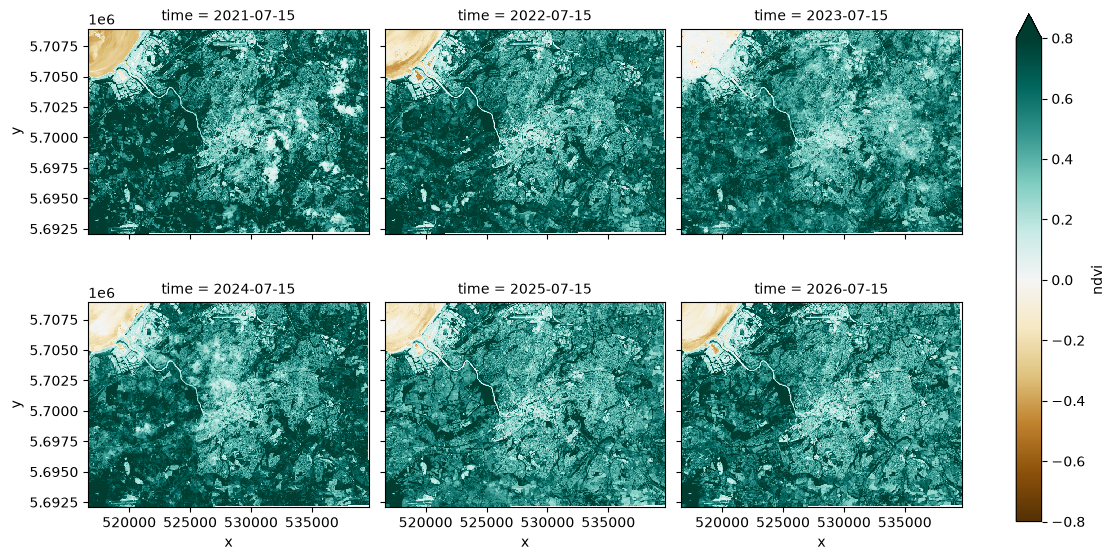

In [24]:
grid = ds.ndvi.plot.imshow(col="time", col_wrap=3, cmap="BrBG", vmin=-0.8, vmax=0.8, figsize=(12, 6))

for ax in grid.axes.flat:
    ax.set_aspect("equal")

plt.show()

We can see that 2025 and 2026 had particualrly low summer NDVI records around Bristol.

Using the tools we learned last week, we can think about how we might further interrogate this data (long-term zonal statistics, perhaps?). GEE will make it easy to produce long time-series from a large stack of GEE imagery - you could just as easily produce a longer time-series going all the way back to the 1990s!

## Summary

We have learned how could begin to take advantage of cloud computing to produce composite images where single images won't do: for instance, where your AOI is too large for a single image; where the scenes are too cloudy for any single image to be sufficient; or simply where you want to obtain a good seasonal average for anlaysis purposes.

We have stuck stricly to the `median()` reduction here, but bear in mind that other reductions are available: `min`, `max`, `mean`, `mode`, `count`...